# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Demo Notebook: Multimedia Visualization — Image, Video and Audio

topics:

1. Multimedia Visualization: From Media to Visual Representation
2. Multimedia Data Characteristics: Spatial, Temporal, Spectral
3. An Image Is a 2D Sampled Signal
4. Raster Images, Pixels and Resolution (Downsampling)
5. Raster Versus Vector
6. Pixel Values, RGB and Luminance
7. Intensity, Brightness and Contrast
8. Image Histograms
9. Same Histogram ≠ Same Image
10. Color Channels and Multichannel Images
11. Image-Based Feature Visualization
12. Image Collections, Contact Sheets and RSVP
13. Image Numericals: Pixels, Storage, Downsampling, Contrast
14. Video as V(x, y, t): Frames, Frame Rate and Temporal Sampling
15. From Frames to Continuous Motion: The Correspondence Problem
16. Video Timelines and Temporal Navigation
17. Keyframes: Uniform vs. Content-Based Selection
18. Motion as Data Encoding: Motion Trajectories
19. Optical Flow and Motion Vectors
20. From Motion to Events
21. Video Numericals
22. Audio as a Time-Series Signal: Samples and Sampling Rate
23. Waveform Visualization
24. Spectrograms
25. Image–Video–Audio Integration (Synchronized Views)
26. Challenges and Design Trade-Offs

**Datasets:**
- **Image:** the Grace Hopper portrait that ships with matplotlib (`matplotlib.cbook.get_sample_data`) — a real
  600 × 512 RGB photograph, so no download is needed.
- **Video:** `unit3_ppt1_cctv_log.csv` — the per-frame log of a **2-minute, 30 fps CCTV clip of a parking lot** (3,600 frames,
  exactly the lecture's Slide 35 example). Each row is one frame: tracked car and person positions, a
  frame-difference `motion_energy` score, the microphone `audio_level_db`, and `mean_brightness`. We re-render
  low-resolution frames from this log, so the "video" is fully reproducible.
- **Audio:** a 10-second, 16 kHz microphone snippet (70–80 s of the same clip) synthesized in Section 22.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

img = plt.imread(cbook.get_sample_data("grace_hopper.jpg"))          # H x W x 3, uint8
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
FPS = 30

print(f"Image: shape={img.shape}, dtype={img.dtype}")
print(f"CCTV log: {len(cctv):,} frames = {len(cctv)/FPS:.0f} s at {FPS} fps")
cctv.head()

Image: shape=(600, 512, 3), dtype=uint8
CCTV log: 3,600 frames = 120 s at 30 fps


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## 1. Multimedia Visualization: From Media to Visual Representation  *(Slides 4–6)*

**What:** Multimedia visualization is not "displaying media" — it transforms perceptually rich media into
representations that expose **structure → pattern → change → event → meaning**. The pipeline is
*Raw multimedia → Encoding → Visual representation → Perception → Interpretation*.

**Why:** Below, we count how many raw values our three media actually contain, then show how much a single
summary visualization (a timeline) reduces that problem — exactly the lecture's surveillance-video example.

RAW MULTIMEDIA (what a human would have to inspect):
  image :         921,600 values  (600 x 512 pixels x 3 channels)
  video :  22,394,880,000 values  (3,600 frames of 1920x1080 RGB)
  audio :       1,920,000 samples (120 s at 16 kHz)

VISUAL REPRESENTATION (what the analyst actually looks at):
  1 timeline of 3,600 motion-energy values + a handful of event markers + representative frames


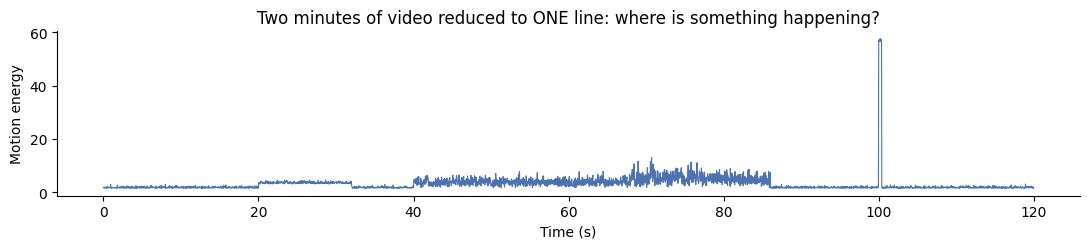

In [2]:
H, W, C = img.shape
n_frames = len(cctv)
raw_video_values = n_frames * 1920 * 1080 * 3        # if the CCTV clip were stored at 1080p RGB
audio_samples = 120 * 16_000                            # 2 minutes of 16 kHz audio

print("RAW MULTIMEDIA (what a human would have to inspect):")
print(f"  image : {H*W*C:>15,} values  ({H} x {W} pixels x {C} channels)")
print(f"  video : {raw_video_values:>15,} values  ({n_frames:,} frames of 1920x1080 RGB)")
print(f"  audio : {audio_samples:>15,} samples (120 s at 16 kHz)")

print("\nVISUAL REPRESENTATION (what the analyst actually looks at):")
print(f"  1 timeline of {n_frames:,} motion-energy values + a handful of event markers + representative frames")

fig, ax = plt.subplots(figsize=(11, 2.6))
ax.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy")
ax.set_title("Two minutes of video reduced to ONE line: where is something happening?")
plt.tight_layout(); plt.show()

## 2. Multimedia Data Characteristics: Spatial, Temporal, Spectral  *(Slides 7–8)*

**What:** Image = spatial (x, y, intensity, colour); Video = spatial + temporal (x, y, t, motion);
Audio = temporal + spectral (t, amplitude, frequency). The key challenge: **preserve the structure that is
meaningful to the modality** — a spatial image should not be reduced to a scalar summary.

**Why:** Below, we destroy the spatial structure of the image by shuffling its pixels. Every scalar summary
(mean, std, min, max) is *identical* — yet the information that mattered is gone.

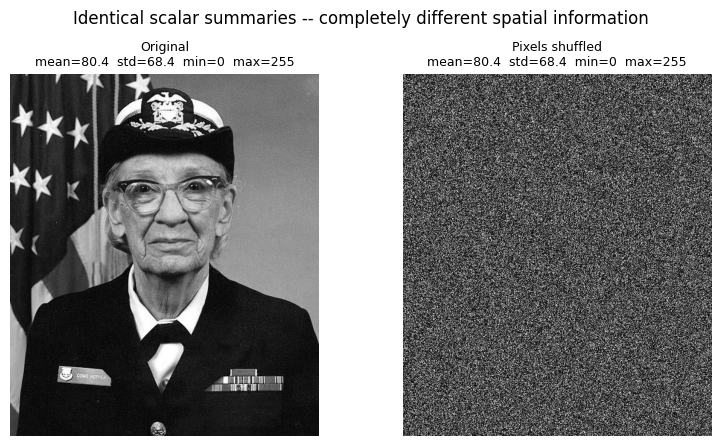

  Modality   Primary structure            Typical variables
     Image             Spatial      x, y, intensity, colour
     Video  Spatial + Temporal              x, y, t, motion
     Audio Temporal + Spectral      t, amplitude, frequency
Multimedia         Cross-modal x, y, t, frequency, modality


In [3]:
gray = img.mean(axis=2)
shuffled = np.random.permutation(gray.ravel()).reshape(gray.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
for ax, im, name in zip(axes, [gray, shuffled], ["Original", "Pixels shuffled"]):
    ax.imshow(im, cmap="gray"); ax.axis("off")
    ax.set_title(f"{name}\nmean={im.mean():.1f}  std={im.std():.1f}  min={im.min():.0f}  max={im.max():.0f}", fontsize=9)
plt.suptitle("Identical scalar summaries -- completely different spatial information")
plt.tight_layout(); plt.show()

print(pd.DataFrame({
    "Modality": ["Image", "Video", "Audio", "Multimedia"],
    "Primary structure": ["Spatial", "Spatial + Temporal", "Temporal + Spectral", "Cross-modal"],
    "Typical variables": ["x, y, intensity, colour", "x, y, t, motion", "t, amplitude, frequency", "x, y, t, frequency, modality"],
}).to_string(index=False))

## 3. An Image Is a 2D Sampled Signal  *(Slide 9)*

**What:** An image is a function **I(x, y)** sampled on a grid; for a colour image every (x, y) holds a vector
(R, G, B). The image is *already* a visualization of underlying measurements, so our task is often to build
**secondary** visualizations of the image data.

**Why:** Below, we zoom into an 8 × 8 patch around Grace Hopper's eye and print the raw numbers behind it —
the "picture" is literally a matrix.

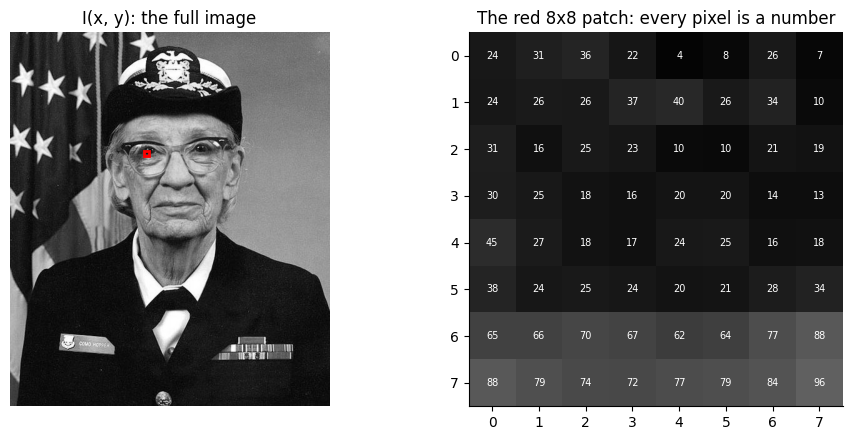

In [4]:
y0, x0 = 190, 215                       # a patch near the left eye
patch = gray[y0:y0+8, x0:x0+8]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(gray, cmap="gray")
axes[0].add_patch(plt.Rectangle((x0, y0), 8, 8, edgecolor="red", facecolor="none", lw=2))
axes[0].set_title("I(x, y): the full image"); axes[0].axis("off")

axes[1].imshow(patch, cmap="gray", vmin=0, vmax=255)
for (r, c), v in np.ndenumerate(patch):
    axes[1].text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=7,
                 color="white" if v < 128 else "black")
axes[1].set_title("The red 8x8 patch: every pixel is a number")
axes[1].set_xticks(range(8)); axes[1].set_yticks(range(8))
plt.tight_layout(); plt.show()

## 4. Raster Images, Pixels and Resolution (Downsampling)  *(Slides 10, 29–30)*

**What:** A raster image is a W × H grid; **spatial resolution** = number of samples. Downsampling removes
samples: going from W × H to W/k × H/k keeps only **1/k²** of the pixels. When we scale back up, new pixels come
from **interpolation** — information that was never sampled cannot be recovered.

**Why:** Below, the image is downsampled by k = 4 and k = 8 and then blown back up to full size.

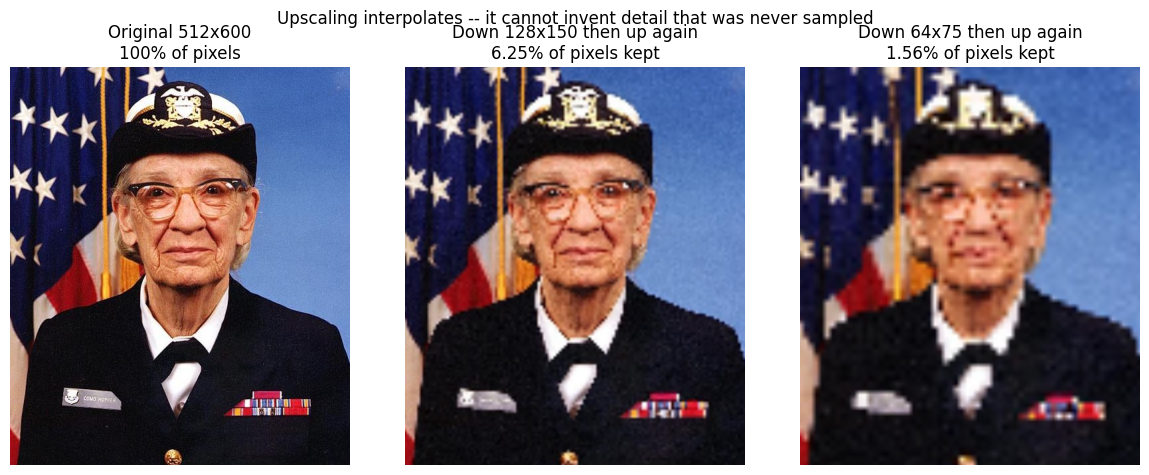

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
axes[0].imshow(img); axes[0].set_title(f"Original {W}x{H}\n100% of pixels"); axes[0].axis("off")
for ax, k in zip(axes[1:], [4, 8]):
    small = img[::k, ::k]
    up = ndimage.zoom(small, (k, k, 1), order=1)            # bilinear interpolation back to full size
    kept = small.shape[0] * small.shape[1] / (H * W) * 100
    ax.imshow(np.clip(up, 0, 255).astype(np.uint8))
    ax.set_title(f"Down {small.shape[1]}x{small.shape[0]} then up again\n{kept:.2f}% of pixels kept")
    ax.axis("off")
plt.suptitle("Upscaling interpolates -- it cannot invent detail that was never sampled")
plt.tight_layout(); plt.show()

## 5. Raster Versus Vector  *(Slides 11–13)*

**What:** Scaling a raster ⇒ new pixels by interpolation. Scaling a vector ⇒ the geometry is simply
**re-rasterized**, so geometric precision is preserved. Trade-off: very complex vector scenes (millions of
primitives) get expensive. *Resolution independence is a property of the representation, not a guarantee of
unlimited detail.*

**Why:** Below, the same circle is stored as a 24 × 24 raster and as a vector (centre + radius), then both are
"zoomed in" 10×.

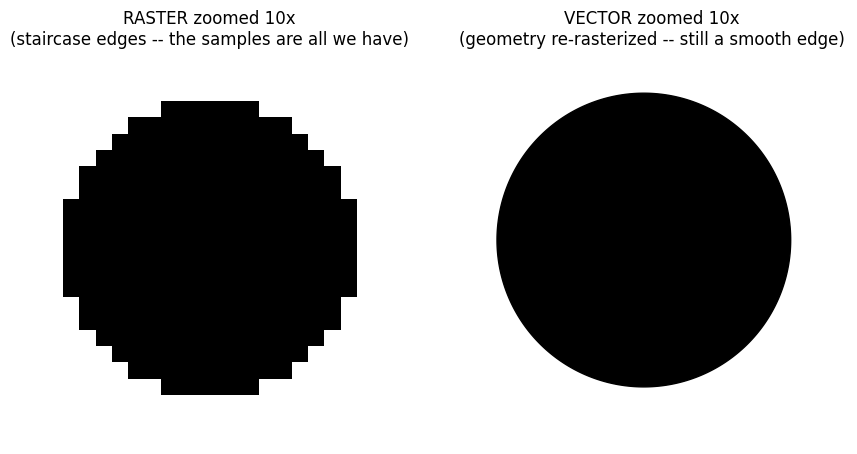

Raster storage: 576 pixel values.  Vector storage: 3 numbers (cx, cy, r).


In [6]:
n = 24
yy, xx = np.mgrid[0:n, 0:n]
raster_circle = ((xx - 11.5) ** 2 + (yy - 11.5) ** 2 <= 9 ** 2).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(np.kron(raster_circle, np.ones((10, 10))), cmap="Greys", interpolation="nearest")
axes[0].set_title("RASTER zoomed 10x\n(staircase edges -- the samples are all we have)"); axes[0].axis("off")

theta = np.linspace(0, 2 * np.pi, 400)
axes[1].fill(115 + 90 * np.cos(theta), 115 + 90 * np.sin(theta), color="black")
axes[1].set_xlim(0, 240); axes[1].set_ylim(240, 0); axes[1].set_aspect("equal"); axes[1].axis("off")
axes[1].set_title("VECTOR zoomed 10x\n(geometry re-rasterized -- still a smooth edge)")
plt.tight_layout(); plt.show()

print(f"Raster storage: {n*n} pixel values.  Vector storage: 3 numbers (cx, cy, r).")

## 6. Pixel Values, RGB and Luminance  *(Slide 14)*

**What:** Pixel value ≠ brightness. An RGB pixel P = (R, G, B) can be converted to a single **luminance**
value; the eye is most sensitive to green and least to blue, so a perceptual conversion weights them
unequally (Rec. 601: **Y = 0.299 R + 0.587 G + 0.114 B**), unlike a naive average.

**Why:** Two images can have identical spatial structure but very different readability if their luminance
distributions differ. Below: naive average vs. weighted luminance, and the same image with its luminance
compressed into a narrow dark band.

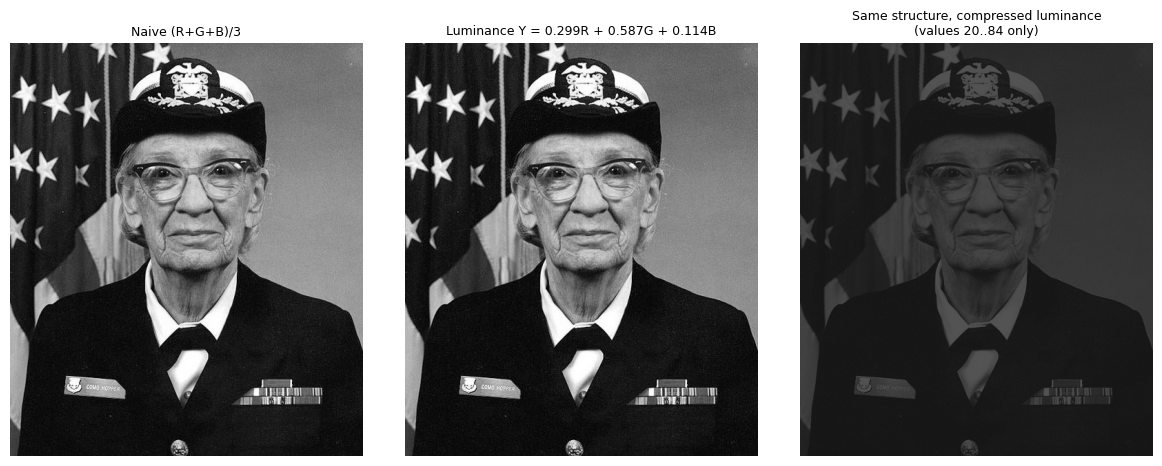

Max |naive - luminance| difference: 31.6 grey levels


In [7]:
R, G, B = [img[..., i].astype(float) for i in range(3)]
lum = 0.299 * R + 0.587 * G + 0.114 * B
naive = (R + G + B) / 3
dark = 20 + 0.25 * lum                          # same structure, squeezed into 20..84

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6))
for ax, im, title in zip(axes, [naive, lum, dark],
                         ["Naive (R+G+B)/3", "Luminance Y = 0.299R + 0.587G + 0.114B",
                          "Same structure, compressed luminance\n(values 20..84 only)"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

print(f"Max |naive - luminance| difference: {np.abs(naive - lum).max():.1f} grey levels")

## 7. Intensity, Brightness and Contrast  *(Slides 15, 31–32)*

**What:** *Intensity* is a number in the signal; *luminance* is the light level on the display;
*brightness* and *lightness* are **perceived**. Early vision responds to **differences**, so contrast drives
edge visibility, feature discrimination, texture and fine-detail readability. A simple luminance contrast
measure is the **Michelson contrast**: **C = (L_max − L_min) / (L_max + L_min)**.

**Why:** Below we compute the slide numericals, then show the classic simultaneous-contrast illusion: the
two centre squares have *exactly the same* intensity but are perceived differently because of their
surroundings.

L_max=180, L_min=60  ->  C = (180-60)/(180+60) = 0.500
L_max=200, L_min=100  ->  C = (200-100)/(200+100) = 0.333
L_max=150, L_min=50  ->  C = (150-50)/(150+50) = 0.500

Original image luminance contrast (1st/99th pct): 0.952   |   compressed 'dark' image: 0.588


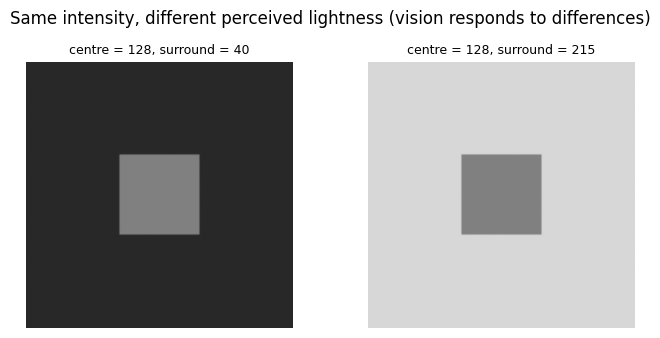

In [8]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

for lmax, lmin in [(180, 60), (200, 100), (150, 50)]:
    print(f"L_max={lmax}, L_min={lmin}  ->  C = ({lmax}-{lmin})/({lmax}+{lmin}) = {michelson(lmax, lmin):.3f}")

print(f"\nOriginal image luminance contrast (1st/99th pct): "
      f"{michelson(*np.percentile(lum, [99, 1])):.3f}   |   compressed 'dark' image: "
      f"{michelson(*np.percentile(dark, [99, 1])):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
for ax, surround in zip(axes, [40, 215]):
    canvas = np.full((100, 100), surround, float); canvas[35:65, 35:65] = 128
    ax.imshow(canvas, cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"centre = 128, surround = {surround}", fontsize=9)
plt.suptitle("Same intensity, different perceived lightness (vision responds to differences)")
plt.tight_layout(); plt.show()

## 8. Image Histograms  *(Slides 16–17)*

**What:** h(k) = number of pixels with intensity k; normalized p(k) = h(k)/N. Left-concentrated ⇒ dark,
right-concentrated ⇒ bright, narrow ⇒ low contrast, wide ⇒ broad dynamic range, two peaks ⇒ two intensity
populations, values piled at 0 or 255 ⇒ **clipping**.

**Why:** Below, four versions of the same photo and their histograms — each histogram shape tells you
what happened to the image before you even look at it. A **contrast stretch** then repairs the dark image.

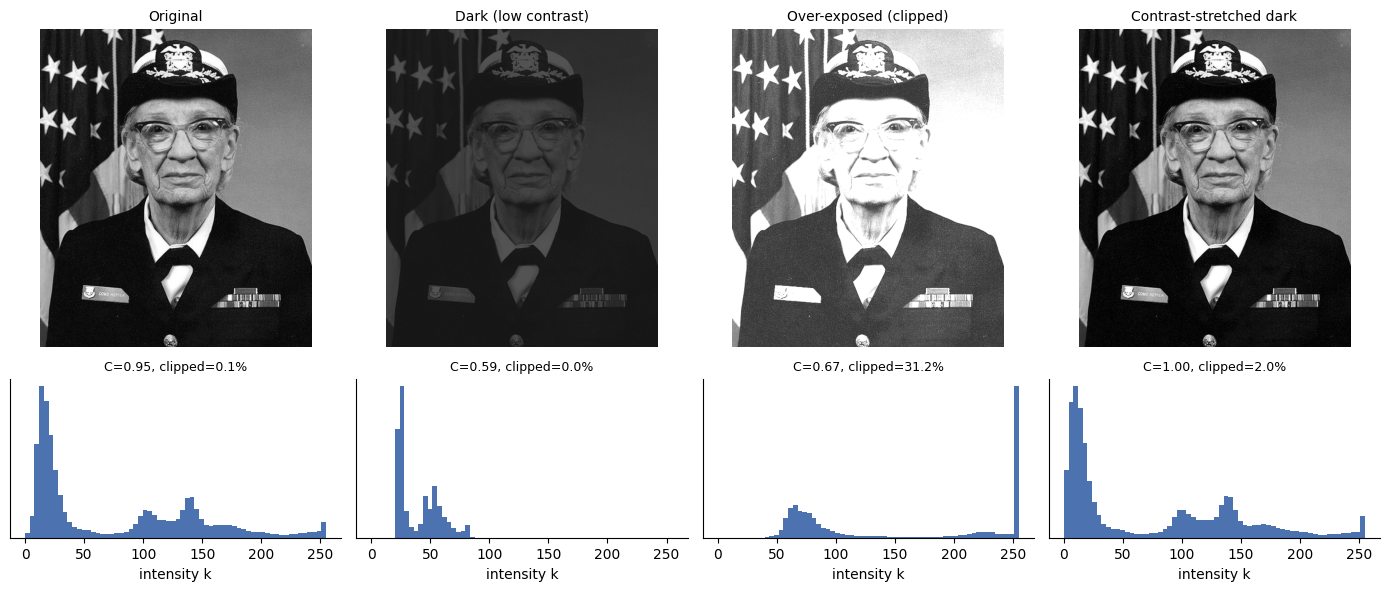

In [9]:
versions = {
    "Original": lum,
    "Dark (low contrast)": dark,
    "Over-exposed (clipped)": np.clip(lum * 1.8 + 40, 0, 255),
    "Contrast-stretched dark": (dark - np.percentile(dark, 1)) / (np.percentile(dark, 99) - np.percentile(dark, 1)) * 255,
}
fig, axes = plt.subplots(2, 4, figsize=(14, 6), gridspec_kw={"height_ratios": [2, 1]})
for col, (name, im) in enumerate(versions.items()):
    im = np.clip(im, 0, 255)
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, col].axis("off")
    axes[0, col].set_title(name, fontsize=10)
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="#4C72B0")
    axes[1, col].set_yticks([]); axes[1, col].set_xlabel("intensity k")
    clipped = ((im <= 0) | (im >= 255)).mean() * 100
    axes[1, col].set_title(f"C={michelson(*np.percentile(im, [99, 1])):.2f}, clipped={clipped:.1f}%", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Same Histogram ≠ Same Image  *(Slide 18)*

**What:** A histogram **removes spatial information**. Two completely different images can have exactly the
same intensity histogram — e.g. a bright object on a dark background vs. the same pixels rearranged.

**Why:** Below, three images built from *the identical multiset of pixel values*: a bright disc on a dark
background, the same pixels sorted into two horizontal bands, and the same pixels scattered at random.
All three histograms match bar for bar.

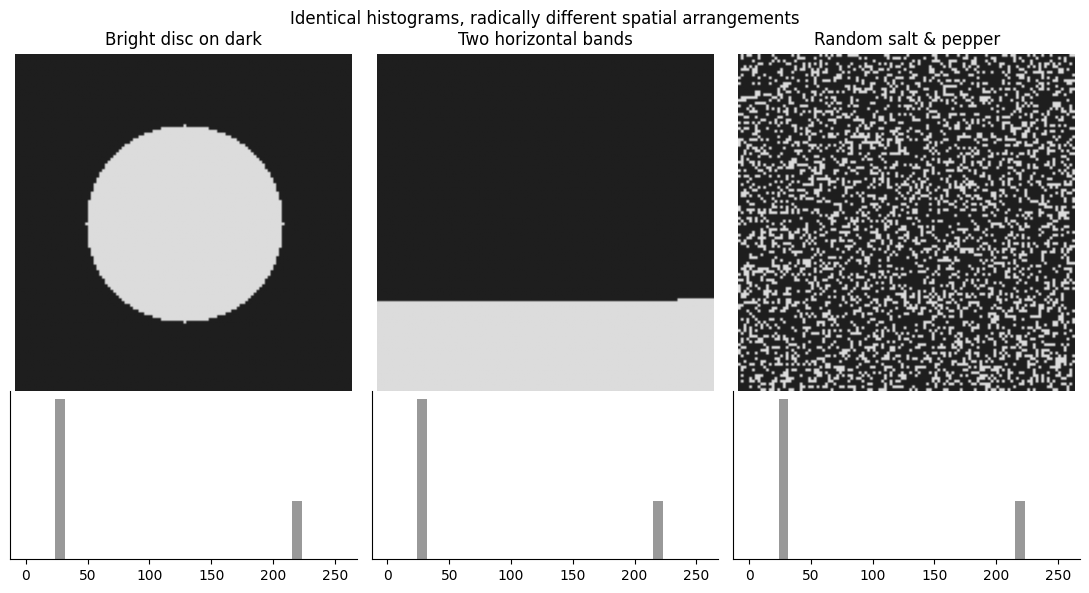

Histograms equal: True


In [10]:
n = 120
yy, xx = np.mgrid[0:n, 0:n]
disc = ((xx - 60) ** 2 + (yy - 60) ** 2 <= 35 ** 2)
disc_img = np.where(disc, 220, 30).astype(float)                       # bright object on dark background
vals = np.sort(disc_img.ravel())
bands_img = vals.reshape(n, n)                                            # same pixels, sorted: dark top, bright bottom
noise_img = np.random.permutation(vals).reshape(n, n)                    # same pixels, random noise

fig, axes = plt.subplots(2, 3, figsize=(11, 6), gridspec_kw={"height_ratios": [2, 1]})
for col, (im, name) in enumerate([(disc_img, "Bright disc on dark"), (bands_img, "Two horizontal bands"), (noise_img, "Random salt & pepper")]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, col].axis("off"); axes[0, col].set_title(name)
    axes[1, col].hist(im.ravel(), bins=32, range=(0, 255), color="#999999"); axes[1, col].set_yticks([])
plt.suptitle("Identical histograms, radically different spatial arrangements")
plt.tight_layout(); plt.show()
print("Histograms equal:", np.array_equal(np.sort(disc_img.ravel()), np.sort(bands_img.ravel())) and np.array_equal(np.sort(bands_img.ravel()), np.sort(noise_img.ravel())))

## 10. Color Channels and Multichannel Images  *(Slides 19–20)*

**What:** A colour image decomposes into R(x,y), G(x,y), B(x,y) — each a grayscale spatial image. Channel views
reveal dominant colour contributions and channel-specific structure. **Perceptual point (Ware):** chromatic
channels have much poorer spatial resolution than luminance → fine detail should rely on luminance; colour is
best for coding categories and attributes.

**Why:** Top row: the three channels. Bottom row: we blur *only the colour* (chroma) vs. *only the luminance*.
Blurring chroma is almost invisible; blurring luminance destroys the detail — Ware's claim, demonstrated.

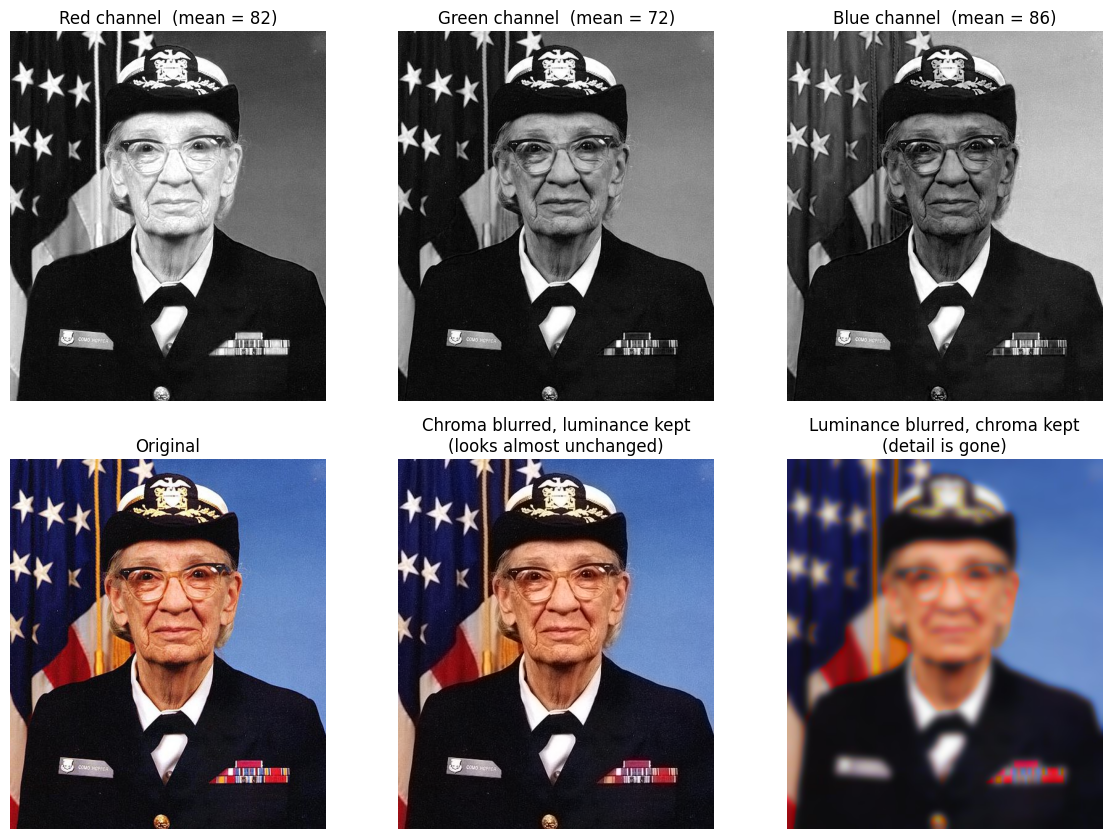

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8.5))
for ax, ch, name in zip(axes[0], [R, G, B], ["Red", "Green", "Blue"]):
    ax.imshow(ch, cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"{name} channel  (mean = {ch.mean():.0f})")

# RGB -> YCbCr (luminance + two chroma channels), blur one part, convert back
Y = lum
Cb = 128 - 0.168736 * R - 0.331264 * G + 0.5 * B
Cr = 128 + 0.5 * R - 0.418688 * G - 0.081312 * B
def to_rgb(Y, Cb, Cr):
    r = Y + 1.402 * (Cr - 128); g = Y - 0.344136 * (Cb - 128) - 0.714136 * (Cr - 128); b = Y + 1.772 * (Cb - 128)
    return np.clip(np.dstack([r, g, b]), 0, 255).astype(np.uint8)
blur = lambda a: ndimage.gaussian_filter(a, 6)

axes[1, 0].imshow(img); axes[1, 0].set_title("Original")
axes[1, 1].imshow(to_rgb(Y, blur(Cb), blur(Cr))); axes[1, 1].set_title("Chroma blurred, luminance kept\n(looks almost unchanged)")
axes[1, 2].imshow(to_rgb(blur(Y), Cb, Cr)); axes[1, 2].set_title("Luminance blurred, chroma kept\n(detail is gone)")
for ax in axes[1]: ax.axis("off")
plt.tight_layout(); plt.show()

## 11. Image-Based Feature Visualization  *(Slides 21–22)*

**What:** Instead of visualizing only I(x, y), construct **derived feature layers** — intensity, local contrast,
edges, orientation, salient regions — and overlay them. Each layer answers a targeted question:
*Where is the structure? Where are the strongest changes? Which regions are distinctive?*

**Why:** Below: Sobel edge magnitude, edge orientation (hue), local contrast (local standard deviation),
and an overlay of the strongest edges on the original image.

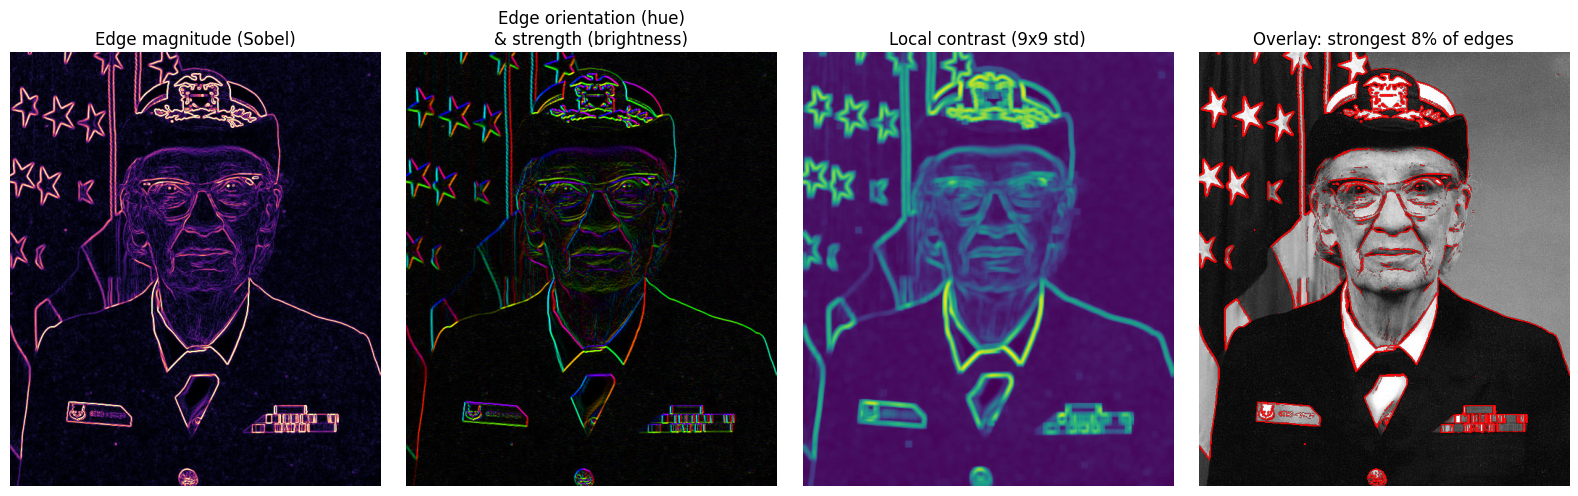

In [12]:
gx = ndimage.sobel(lum, axis=1); gy = ndimage.sobel(lum, axis=0)
edge_mag = np.hypot(gx, gy)
orient = (np.arctan2(gy, gx) + np.pi) / (2 * np.pi)             # 0..1 -> hue
local_contrast = np.sqrt(np.maximum(ndimage.uniform_filter(lum ** 2, 9) - ndimage.uniform_filter(lum, 9) ** 2, 0))

import matplotlib.colors as mcolors
hsv = np.dstack([orient, np.ones_like(orient), np.clip(edge_mag / np.percentile(edge_mag, 99), 0, 1)])

fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
axes[0].imshow(edge_mag, cmap="magma", vmax=np.percentile(edge_mag, 99)); axes[0].set_title("Edge magnitude (Sobel)")
axes[1].imshow(mcolors.hsv_to_rgb(hsv)); axes[1].set_title("Edge orientation (hue)\n& strength (brightness)")
axes[2].imshow(local_contrast, cmap="viridis"); axes[2].set_title("Local contrast (9x9 std)")
axes[3].imshow(lum, cmap="gray")
strong = edge_mag > np.percentile(edge_mag, 92)
axes[3].imshow(np.ma.masked_where(~strong, strong), cmap="autumn", alpha=0.9); axes[3].set_title("Overlay: strongest 8% of edges")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 12. Image Collections, Contact Sheets and RSVP  *(Slides 23–24)*

**What:** **Thumbnail grids / contact sheets** show many images at once for comparison; **image timelines**
order them by time. **RSVP** shows images one after another at high speed — people can detect targets at
≈ 10 images/s, but an **attentional blink** hides a second target that arrives too soon after the first.
Complex objects are recognized best at ≈ 4–6° of visual angle → more thumbnails = more overview, less detail.

**Why:** Below we render the CCTV clip as a **contact sheet** (one thumbnail every 5 s) — an image timeline
of the whole 2 minutes — and compute how long RSVP would take vs. watching every frame.

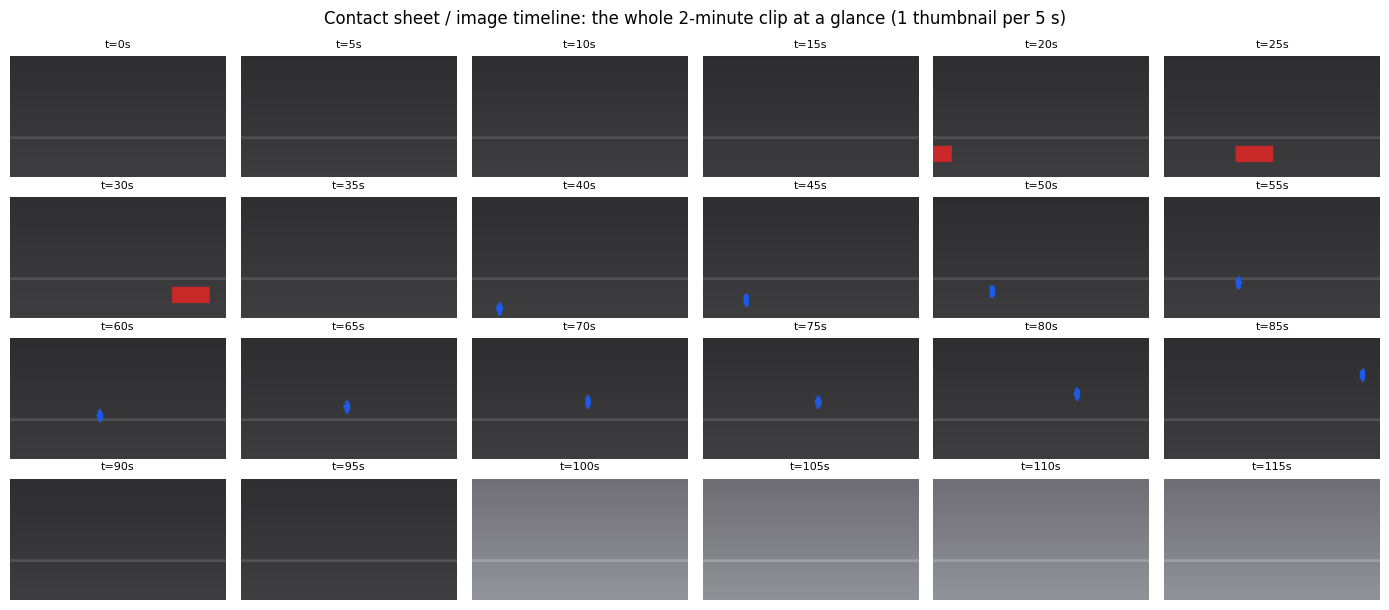

Watching every frame at 30 fps: 120 s.  RSVP of the 24 thumbnails at 10 img/s: 2.4 s.


In [13]:
FRAME_H, FRAME_W = 90, 160                      # render frames at 1/4 of the 640x360 camera resolution

def render_frame(row):
    """Re-render one low-resolution CCTV frame from the tracking log."""
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)                  # lot lighting
    frame = np.dstack([base, base, base * 1.05])
    frame[60:62, :, :] += 25                                                   # painted kerb line
    if not np.isnan(row.car_x):
        cx, cy = row.car_x / 4, row.car_y / 4
        m = (np.abs(xx - cx) < 14) & (np.abs(yy - cy) < 6)
        frame[m] = [200, 40, 40]
    if not np.isnan(row.person_x):
        px, py = row.person_x / 4, row.person_y / 4
        m = ((xx - px) / 2.2) ** 2 + ((yy - py) / 5) ** 2 <= 1
        frame[m] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

sheet_idx = np.arange(0, len(cctv), 5 * FPS)                                  # every 5 s
fig, axes = plt.subplots(4, 6, figsize=(14, 6.2))
for ax, i in zip(axes.flat, sheet_idx):
    ax.imshow(render_frame(cctv.iloc[i])); ax.set_title(f"t={cctv.time_s[i]:.0f}s", fontsize=8); ax.axis("off")
plt.suptitle("Contact sheet / image timeline: the whole 2-minute clip at a glance (1 thumbnail per 5 s)")
plt.tight_layout(); plt.show()

print(f"Watching every frame at 30 fps: {len(cctv)/30:.0f} s.  RSVP of the {len(sheet_idx)} thumbnails at 10 img/s: "
      f"{len(sheet_idx)/10:.1f} s.")

## 13. Image Numericals: Pixels, Storage, Downsampling, Contrast  *(Slides 25–32)*

**What:** N = W × H pixels; uncompressed storage = **W × H × C × B** bytes (C channels, B bytes/channel);
downsampling keeps (W'H')/(WH) of the pixels; Michelson contrast C = (L_max − L_min)/(L_max + L_min).

**Why:** Below, one small function reproduces every worked answer and "extra question" from the slides, so
you can check your hand calculations.

In [14]:
MB = 1024 ** 2
def image_bytes(w, h, channels=1, bits_per_channel=8):
    return w * h * channels * bits_per_channel / 8

print("1) Pixels and data")
print(f"   1920x1080 -> {1920*1080:,} px; at 8 bpp = {1920*1080*8:,} bits = {image_bytes(1920,1080)/MB:.2f} MB")
print(f"   1000x800 gray 8-bit  -> {image_bytes(1000,800)/MB:.2f} MB")
print(f"   640x480 RGB 24-bit   -> {image_bytes(640,480,3)/MB:.2f} MB")
print("2) Uncompressed RGB storage W x H x C x B")
for w, h, c in [(1920, 1080, 3), (1280, 720, 3), (1024, 768, 1)]:
    print(f"   {w}x{h}x{c}x1 = {image_bytes(w,h,c):,.0f} bytes = {image_bytes(w,h,c)/MB:.2f} MB")
print("3) Downsampling: % of pixels remaining")
for (w, h), (w2, h2) in [((4000, 3000), (1000, 750)), ((2000, 1500), (1000, 750)), ((1600, 1200), (800, 600))]:
    pct = w2 * h2 / (w * h) * 100
    print(f"   {w}x{h} -> {w2}x{h2}: {pct:.2f}% remain, {100-pct:.2f}% removed")
print("4) Contrast")
for lmax, lmin in [(180, 60), (200, 100), (150, 50)]:
    print(f"   L_max={lmax}, L_min={lmin}: C = {michelson(lmax, lmin):.3f}")

1) Pixels and data
   1920x1080 -> 2,073,600 px; at 8 bpp = 16,588,800 bits = 1.98 MB
   1000x800 gray 8-bit  -> 0.76 MB
   640x480 RGB 24-bit   -> 0.88 MB
2) Uncompressed RGB storage W x H x C x B
   1920x1080x3x1 = 6,220,800 bytes = 5.93 MB
   1280x720x3x1 = 2,764,800 bytes = 2.64 MB
   1024x768x1x1 = 786,432 bytes = 0.75 MB
3) Downsampling: % of pixels remaining
   4000x3000 -> 1000x750: 6.25% remain, 93.75% removed
   2000x1500 -> 1000x750: 25.00% remain, 75.00% removed
   1600x1200 -> 800x600: 25.00% remain, 75.00% removed
4) Contrast
   L_max=180, L_min=60: C = 0.500
   L_max=200, L_min=100: C = 0.333
   L_max=150, L_min=50: C = 0.500


## 14. Video as V(x, y, t): Frames, Frame Rate and Temporal Sampling  *(Slides 33–35)*

**What:** A video is an ordered sequence of frames, **V(x, y, t)**. Frame rate f (fps) sets the temporal
resolution: Δt = 1/f (33.3 ms at 30 fps), N = f × T frames. Image visualization asks *what is where*; video
visualization adds *how does it change over time?*

**Why:** Below we stack rendered frames into an actual 3-D array V[t, y, x], then take an **x–t slice**
(one scan-line through time). Moving objects become slanted streaks — the slope is their speed.

V(x, y, t) array: (1200, 90, 160)  ->  17,280,000 values even at 160x90 and 10 fps
30 fps -> dt = 33.3 ms between frames;  N = f*T = 30*120 = 3,600 frames


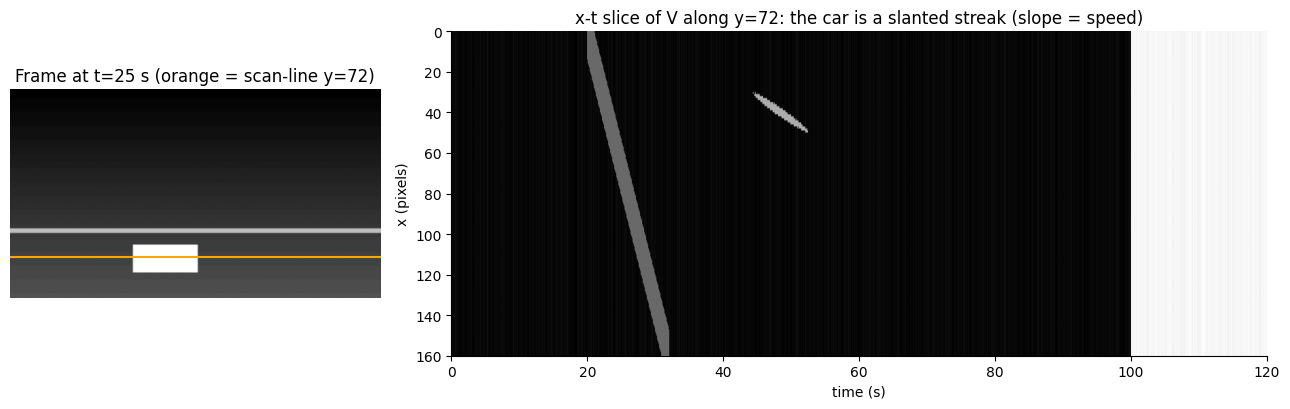

In [15]:
sub = cctv.iloc[::3]                                         # every 3rd frame -> 10 fps, 1,200 frames
V = np.stack([render_frame(r).mean(axis=2) for r in sub.itertuples()])    # shape (t, y, x)
print(f"V(x, y, t) array: {V.shape}  ->  {V.size:,} values even at 160x90 and 10 fps")
print(f"30 fps -> dt = {1000/30:.1f} ms between frames;  N = f*T = 30*120 = {30*120:,} frames")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].imshow(V[sub.time_s.searchsorted(25)], cmap="gray"); axes[0].axhline(72, color="orange")
axes[0].set_title("Frame at t=25 s (orange = scan-line y=72)"); axes[0].axis("off")
axes[1].imshow(V[:, 72, :].T, cmap="gray", aspect="auto", extent=[0, 120, FRAME_W, 0])
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("x (pixels)")
axes[1].set_title("x-t slice of V along y=72: the car is a slanted streak (slope = speed)")
plt.tight_layout(); plt.show()

## 15. From Frames to Continuous Motion: The Correspondence Problem  *(Slides 36–37)*

**What:** Video contains no continuous motion — only discrete frames. The visual system must decide which
element in frame t+1 *corresponds* to which in frame t (Ware's **correspondence problem**). If identical
elements move too far between frames, they get matched to the wrong neighbour and motion looks ambiguous or
**reversed**. A higher frame rate is not automatically sufficient — frame-to-frame displacement must stay
interpretable.

**Why:** Below, a ring of 12 identical dots rotates clockwise. We match each dot to its nearest neighbour in the
next frame (what perception effectively does). Small steps → correct direction; once the step exceeds half the
dot spacing (15°), the *perceived* rotation flips.

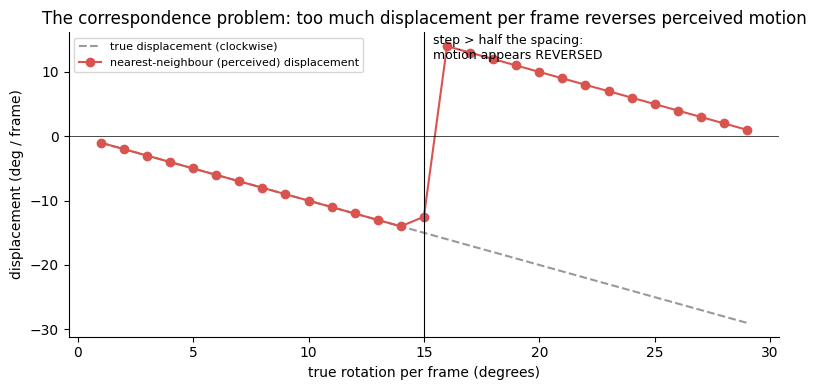

In [16]:
n_dots = 12
spacing = 360 / n_dots
def perceived_step(step_deg):
    a0 = np.arange(n_dots) * spacing
    a1 = a0 - step_deg                                  # true motion: clockwise
    diff = (a1[None, :] - a0[:, None] + 180) % 360 - 180
    j = np.abs(diff).argmin(axis=1)                     # nearest-neighbour correspondence
    return diff[np.arange(n_dots), j].mean()

steps = np.arange(1, 30)
perceived = [perceived_step(s) for s in steps]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, -steps, "--", color="#999999", label="true displacement (clockwise)")
ax.plot(steps, perceived, "o-", color="#D9534F", label="nearest-neighbour (perceived) displacement")
ax.axvline(spacing / 2, color="black", lw=0.8); ax.axhline(0, color="black", lw=0.5)
ax.text(spacing / 2 + 0.4, 12, "step > half the spacing:\nmotion appears REVERSED", fontsize=9)
ax.set_xlabel("true rotation per frame (degrees)"); ax.set_ylabel("displacement (deg / frame)")
ax.set_title("The correspondence problem: too much displacement per frame reverses perceived motion")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 16. Video Timelines and Temporal Navigation  *(Slides 38–39)*

**What:** A timeline turns a long frame sequence into a **navigable temporal structure**: time becomes a
spatial axis, frames are indexed by time (t = n / f), and markers show events, annotations or segments.
This matters most when the user is *searching* for an event rather than watching sequentially.

**Why:** Below, the CCTV clip as a multi-track timeline (presence of car/person, motion energy, audio level,
brightness) — the same idea as a video editor's track view.

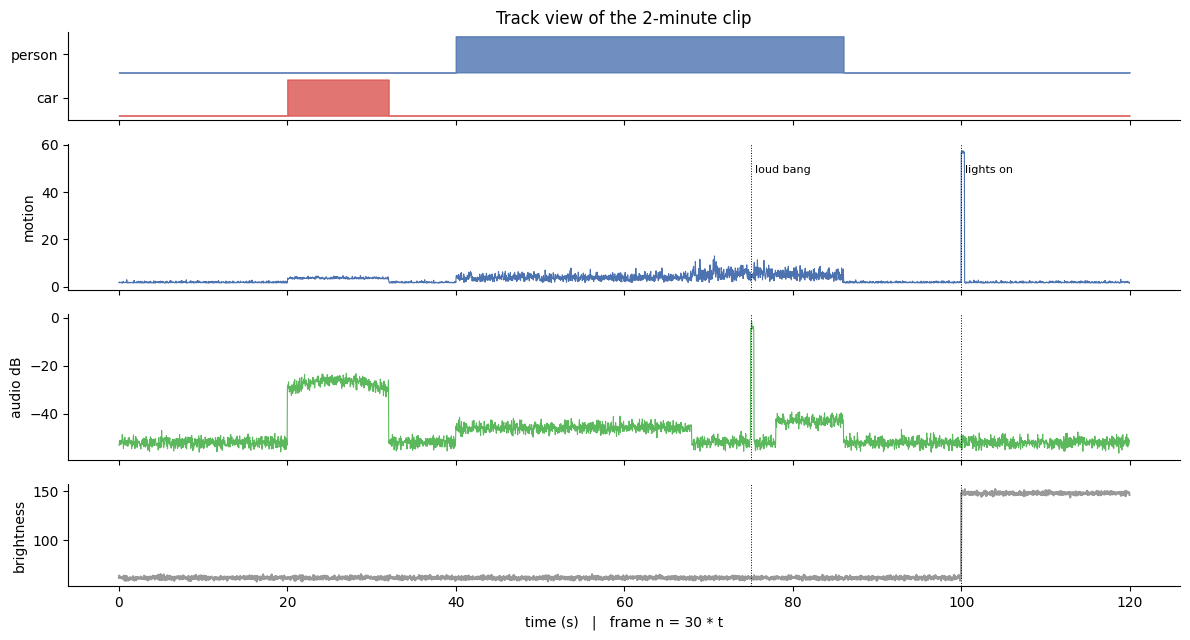

frame  150 at 30 fps  ->  t = 5.00 s
frame 2250 at 30 fps  ->  t = 75.00 s
frame 3000 at 30 fps  ->  t = 100.00 s


In [17]:
fig, axes = plt.subplots(4, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [0.6, 1, 1, 0.7]})
axes[0].fill_between(cctv.time_s, 0, cctv.car_x.notna(), step="mid", color="#D9534F", alpha=0.8, label="car")
axes[0].fill_between(cctv.time_s, 1.2, 1.2 + cctv.person_x.notna(), step="mid", color="#4C72B0", alpha=0.8, label="person")
axes[0].set_yticks([0.5, 1.7]); axes[0].set_yticklabels(["car", "person"]); axes[0].set_title("Track view of the 2-minute clip")
axes[1].plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.8); axes[1].set_ylabel("motion")
axes[2].plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.8); axes[2].set_ylabel("audio dB")
axes[3].plot(cctv.time_s, cctv.mean_brightness, color="#999999"); axes[3].set_ylabel("brightness")
axes[3].set_xlabel("time (s)   |   frame n = 30 * t")
for t_mark, lbl in [(75, "loud bang"), (100, "lights on")]:
    for ax in axes[1:]: ax.axvline(t_mark, color="black", lw=0.7, ls=":")
    axes[1].text(t_mark + 0.5, axes[1].get_ylim()[1] * 0.8, lbl, fontsize=8)
plt.tight_layout(); plt.show()

for frame_no in [150, 2250, 3000]:
    print(f"frame {frame_no:>4} at 30 fps  ->  t = {frame_no/30:.2f} s")

## 17. Keyframes: Uniform vs. Content-Based Selection  *(Slide 40)*

**What:** A keyframe represents an important visual state or transition. **Uniform sampling** takes every k-th
frame (n = 0, k, 2k, …). **Content-based selection** picks frames where the scene changes, motion is large, or
a new object appears.

**Why:** Below we choose 6 keyframes both ways. Uniform sampling wastes thumbnails on an empty lot; content-based
selection (peaks of the frame-to-frame difference + new-object onsets) lands on the moments that matter.

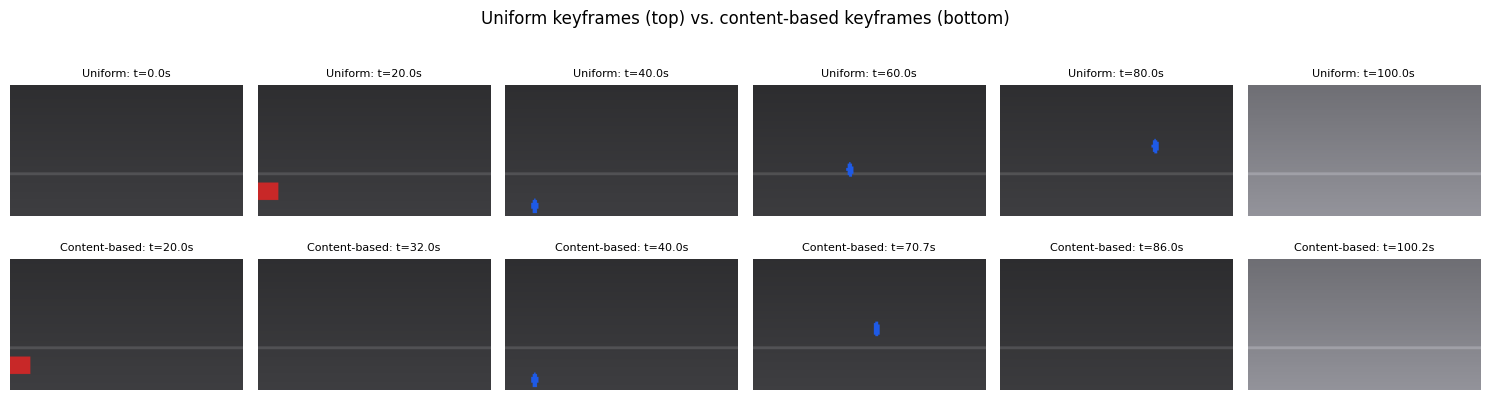

In [18]:
k = len(cctv) // 6
uniform_idx = np.arange(0, len(cctv), k)[:6]

# content-based: object onsets/offsets + biggest motion peaks, at least 4 s apart
onsets = []
for col in ["car_x", "person_x"]:
    present = cctv[col].notna().astype(int).diff().fillna(0)
    onsets += list(cctv.index[present != 0])
peaks, _ = signal.find_peaks(cctv.motion_energy, distance=4 * FPS)
peaks = peaks[np.argsort(cctv.motion_energy.values[peaks])[::-1]]       # strongest motion first
chosen = []
for i in list(onsets) + list(peaks):                                      # priority: new objects, then motion
    if len(chosen) < 6 and all(abs(i - j) > 4 * FPS for j in chosen):
        chosen.append(i)
content_idx = sorted(chosen)

fig, axes = plt.subplots(2, 6, figsize=(15, 4.4))
for row, (idx, name) in enumerate([(uniform_idx, "Uniform"), (content_idx, "Content-based")]):
    for ax, i in zip(axes[row], idx):
        ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
        ax.set_title(f"{name}: t={cctv.time_s[i]:.1f}s", fontsize=8)
plt.suptitle("Uniform keyframes (top) vs. content-based keyframes (bottom)")
plt.tight_layout(); plt.show()

## 18. Motion as Data Encoding: Motion Trajectories  *(Slides 41–43)*

**What:** Motion is a visual channel: direction, (qualitative) magnitude, temporal progression, grouping.
Ware: animation communicates **direction** well but is **poor for precise speed judgments** — so encode precise
quantities with another channel. A **trajectory** is the path P(t) = (x(t), y(t)); it exposes direction, turning
points, path length and repeated patterns. In 3-D (x, y, t) a trajectory becomes a **space–time path**.

**Why:** Left: the person's 2-D trajectory, coloured by time (colour carries the precise timing that motion
alone could not). Right: the same path in an (x, y, t) space–time cube — the vertical segment is the 10 s the
person stood still.

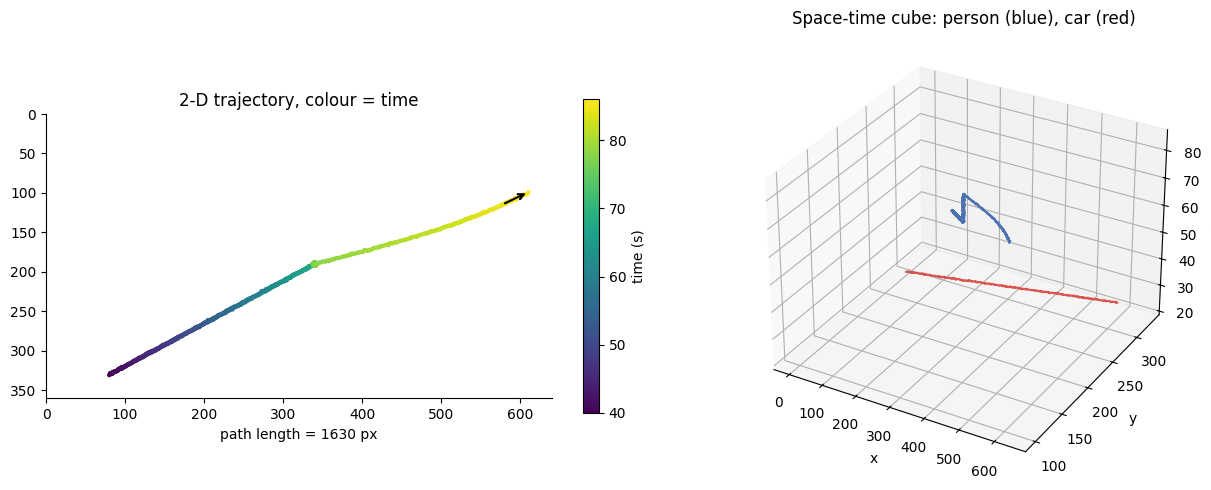

In [19]:
p = cctv.dropna(subset=["person_x"])
fig = plt.figure(figsize=(13, 5))
ax1 = fig.add_subplot(1, 2, 1)
sc = ax1.scatter(p.person_x, p.person_y, c=p.time_s, cmap="viridis", s=4)
ax1.annotate("", xy=(p.person_x.iloc[-1], p.person_y.iloc[-1]), xytext=(p.person_x.iloc[-40], p.person_y.iloc[-40]),
             arrowprops=dict(arrowstyle="->", color="black", lw=1.5))
ax1.set_xlim(0, 640); ax1.set_ylim(360, 0); ax1.set_aspect("equal")
ax1.set_title("2-D trajectory, colour = time"); plt.colorbar(sc, ax=ax1, label="time (s)", shrink=0.7)
path_len = np.hypot(np.diff(p.person_x), np.diff(p.person_y)).sum()
ax1.set_xlabel(f"path length = {path_len:.0f} px")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(p.person_x, p.person_y, p.time_s, color="#4C72B0")
c = cctv.dropna(subset=["car_x"]); ax2.plot(c.car_x, c.car_y, c.time_s, color="#D9534F")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("t (s)")
ax2.set_title("Space-time cube: person (blue), car (red)")
plt.tight_layout(); plt.show()

## 19. Optical Flow and Motion Vectors  *(Slides 44–46)*

**What:** Optical flow is the apparent motion of image patterns between consecutive frames. Each location gets
a motion vector (u, v): a feature at (120, 80) → (126, 83) has u = 6, v = 3, |v| = √(6² + 3²) ≈ 6.7 px/frame.
A flow field is drawn as **arrows** (direction + length) or **colour-coded** (hue = direction,
brightness = magnitude).

**Why:** Below we create frame 2 by moving *only the face region* of the portrait by (6, 3) px, then estimate flow
with simple **block matching** (for each 16×16 block, find the shift that best matches the next frame). The
estimated field recovers exactly the slide's (6, 3) vector — and zero motion in the static background.

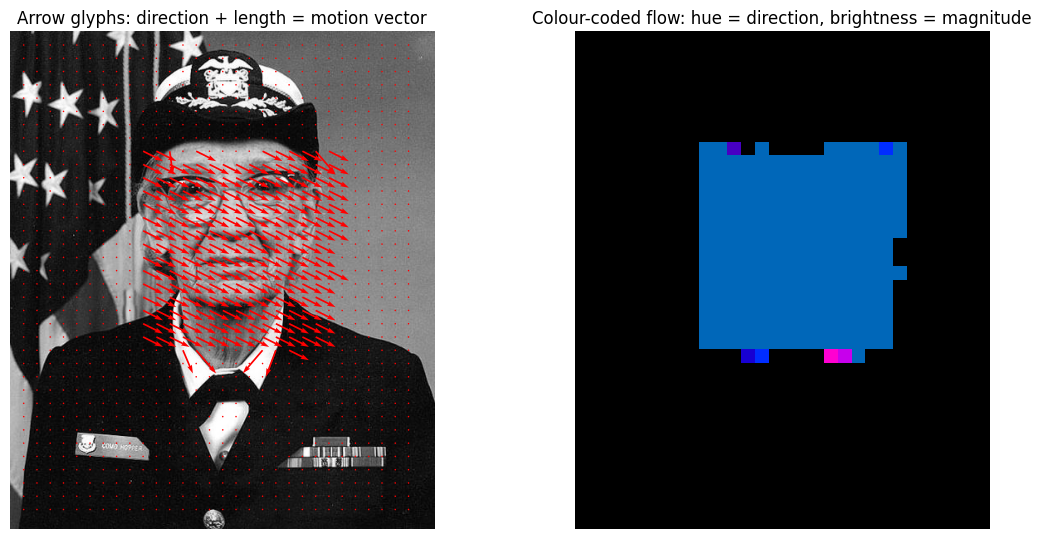

Most common vector in the moving region: (u, v) = (6, 3)  -> |v| = 6.71 px/frame;  static blocks: 862 of 1080


In [20]:
f1 = lum.copy()
f2 = lum.copy()
r0, r1, c0, c1 = 140, 380, 150, 380                        # moving face region
f2[r0 + 3:r1 + 3, c0 + 6:c1 + 6] = lum[r0:r1, c0:c1]       # shift by (u, v) = (6, 3)

B_, S = 16, 8                                               # block size, search radius
ys, xs, us, vs = [], [], [], []
for by in range(S, f1.shape[0] - B_ - S, B_):
    for bx in range(S, f1.shape[1] - B_ - S, B_):
        block = f1[by:by + B_, bx:bx + B_]
        best, best_uv = np.inf, (0, 0)
        for dv in range(-S, S + 1):
            for du in range(-S, S + 1):
                err = np.abs(f2[by + dv:by + dv + B_, bx + du:bx + du + B_] - block).sum()
                if err < best - 1e-6:
                    best, best_uv = err, (du, dv)
        ys.append(by + B_ / 2); xs.append(bx + B_ / 2); us.append(best_uv[0]); vs.append(best_uv[1])
us, vs = np.array(us), np.array(vs)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].imshow(lum, cmap="gray")
axes[0].quiver(xs, ys, us, vs, color="red", angles="xy", scale_units="xy", scale=0.25, width=0.004)
axes[0].set_title("Arrow glyphs: direction + length = motion vector"); axes[0].axis("off")
mag = np.hypot(us, vs); ang = (np.arctan2(vs, us) + np.pi) / (2 * np.pi)
grid_shape = (len(set(ys)), len(set(xs)))
hsv = np.dstack([ang.reshape(grid_shape), np.ones(grid_shape), (mag / max(mag.max(), 1)).reshape(grid_shape)])
axes[1].imshow(mcolors.hsv_to_rgb(hsv), interpolation="nearest")
axes[1].set_title("Colour-coded flow: hue = direction, brightness = magnitude"); axes[1].axis("off")
plt.tight_layout(); plt.show()

moving = mag > 0
print(f"Most common vector in the moving region: (u, v) = ({np.median(us[moving]):.0f}, {np.median(vs[moving]):.0f})"
      f"  -> |v| = {np.hypot(6, 3):.2f} px/frame;  static blocks: {(~moving).sum()} of {len(us)}")

## 20. From Motion to Events  *(Slide 47)*

**What:** Motion information identifies **events**: sudden movement, objects entering/leaving, scene transitions,
periods of inactivity. Instead of presenting the entire video:
**Video → Motion analysis → Event detection → Timeline + representative frames.**

**Why:** Below we compute the person's speed from their motion vector over a 1-second window (30 frames — a
single frame's displacement is dominated by tracking jitter), segment it into walking / standing / running, combine with the motion and audio channels, and produce a compact
**event table + annotated timeline** — the 2-minute clip becomes 7 rows.

,time_s,frame,event
0,20.0,600,car enters
1,32.0,961,car leaves
2,40.0,1200,person enters
3,68.9,2066,person starts standing
4,75.0,2250,loud audio impulse
5,78.6,2358,person starts running
6,86.0,2581,person leaves
7,100.0,3000,scene lighting change


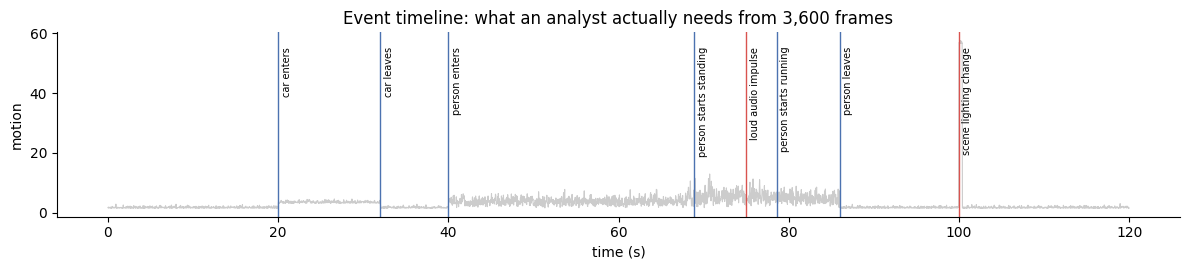

In [21]:
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))          # px moved in the last 1 s = px/s
state = pd.cut(speed, [-0.1, 3, 25, np.inf], labels=["standing", "walking", "running"])

events = []
def add(t, what): events.append({"time_s": round(t, 1), "frame": int(round(t * FPS)), "event": what})
for col, name in [("car_x", "car"), ("person_x", "person")]:
    pres = cctv[col].notna().astype(int).diff()
    for i in cctv.index[pres == 1]: add(cctv.time_s[i], f"{name} enters")
    for i in cctv.index[pres == -1]: add(cctv.time_s[i], f"{name} leaves")
seg = state.astype(object).where(state.notna())
run_id = seg.ne(seg.shift()).cumsum()
seg = seg.where(seg.groupby(run_id).transform("size") >= FPS).ffill().where(state.notna())  # drop <1 s flickers
change = seg.ne(seg.shift()) & seg.notna() & seg.shift().notna()
for i in cctv.index[change]: add(cctv.time_s[i], f"person starts {seg[i]}")
loud = cctv.index[(cctv.audio_level_db > -20) & (cctv.audio_level_db.shift() <= -20)]
for i in loud: add(cctv.time_s[i], "loud audio impulse")
glob = cctv.index[(cctv.mean_brightness.diff() > 40)]
for i in glob: add(cctv.time_s[i], "scene lighting change")
events = pd.DataFrame(events).sort_values("time_s").reset_index(drop=True)
display(events)

fig, ax = plt.subplots(figsize=(12, 2.8))
ax.plot(cctv.time_s, cctv.motion_energy, color="#cccccc", lw=0.8)
for _, e in events.iterrows():
    ax.axvline(e.time_s, color="#D9534F" if "audio" in e.event or "lighting" in e.event else "#4C72B0", lw=1)
    ax.text(e.time_s + 0.4, ax.get_ylim()[1] * 0.92, e.event, rotation=90, va="top", fontsize=7)
ax.set_xlabel("time (s)"); ax.set_ylabel("motion"); ax.set_title("Event timeline: what an analyst actually needs from 3,600 frames")
plt.tight_layout(); plt.show()

## 21. Video Numericals  *(Slides 48–51)*

**What:** Frame count **N = f T**; frame–time conversion **t = n / f**; interval **Δt = 1/f**; motion vector
**(u, v) = (x₂ − x₁, y₂ − y₁)** with magnitude **√(u² + v²)**.

**Why:** All eight "extra questions" from the slides, solved in code.

In [22]:
print("1) 5-min video at 20 fps:", 20 * 5 * 60, "frames")
print("2) 90 s with 2,700 frames:", 2700 / 90, "fps")
print("3) 1,500 frames at 25 fps:", 1500 / 25, "s of video")
print("4) frame 100 at 25 fps:", 100 / 25, "s elapsed")
print("5) keyframe 450 at 30 fps:", 450 / 30, "s")
print(f"6) 60 fps -> interval = 1/60 s = {1000/60:.2f} ms")
u, v = 92 - 100, 80 - 80
print(f"7) (100,80)->(92,80): (u, v) = ({u}, {v}) -> moves {abs(u)} px to the LEFT")
u, v = 43 - 40, 54 - 50
print(f"8) (40,50)->(43,54): (u, v) = ({u}, {v}) -> |v| = sqrt({u}^2+{v}^2) = {np.hypot(u, v):.0f} px/frame")

1) 5-min video at 20 fps: 6000 frames
2) 90 s with 2,700 frames: 30.0 fps
3) 1,500 frames at 25 fps: 60.0 s of video
4) frame 100 at 25 fps: 4.0 s elapsed
5) keyframe 450 at 30 fps: 15.0 s
6) 60 fps -> interval = 1/60 s = 16.67 ms
7) (100,80)->(92,80): (u, v) = (-8, 0) -> moves 8 px to the LEFT
8) (40,50)->(43,54): (u, v) = (3, 4) -> |v| = sqrt(3^2+4^2) = 5 px/frame


## 22. Audio as a Time-Series Signal: Samples and Sampling Rate  *(Slides 52–55)*

**What:** Digital audio is a sequence of amplitude samples **x[n]** taken at a fixed **sampling rate** f_s (Hz).
Each sample has a time position (n / f_s) and an amplitude. Number of samples = **f_s × T** — e.g. a 2 s
recording at 16 kHz has 32,000 samples.

**Why:** Below we synthesize the 10 seconds of microphone audio around the "loud bang" (70–80 s of the CCTV clip)
and zoom in until the individual samples are visible.

Samples = f_s x T = 16,000 x 10 s = 160,000
Slide example: 2 s at 16 kHz = 32,000 samples


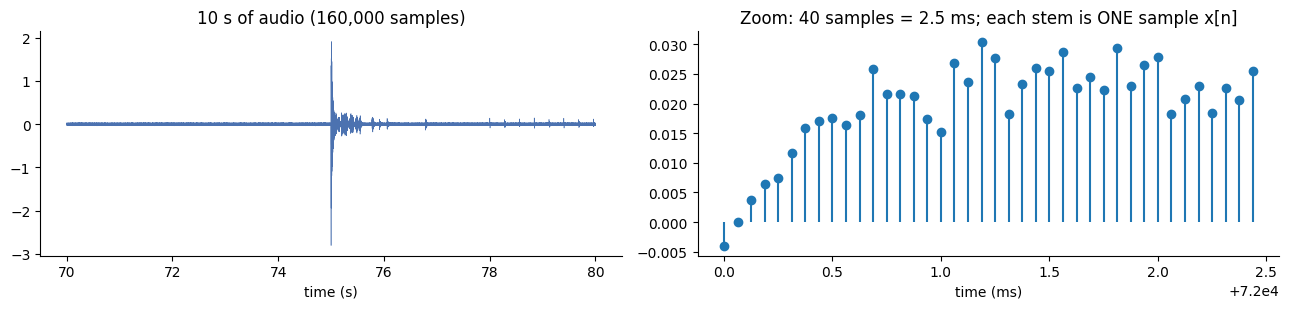

In [23]:
FS = 16_000
def cctv_audio(t_start=70.0, t_end=80.0, seed=0):
    """Microphone audio for part of the CCTV clip: hum + footsteps + glass break at 75 s."""
    rng = np.random.default_rng(seed)
    t = t_start + np.arange(int((t_end - t_start) * FS)) / FS
    x = 0.02 * np.sin(2 * np.pi * 120 * t) + 0.01 * np.sin(2 * np.pi * 240 * t)     # electrical hum
    x += 0.004 * rng.normal(size=t.size)                                             # background noise
    for step in np.arange(78.0, t_end, 0.28):                                        # running footsteps
        m = (t >= step) & (t < step + 0.04)
        x[m] += 0.15 * np.exp(-(t[m] - step) / 0.01) * np.sin(2 * np.pi * 90 * (t[m] - step))
    m = t >= 75.0                                                                    # impact (broadband)
    x[m] += 0.9 * np.exp(-(t[m] - 75.0) / 0.03) * rng.normal(size=m.sum())
    for k in range(40):                                                              # glass tinkle: 3-7 kHz
        t0 = 75.05 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
        mk = (t >= t0) & (t < t0 + 0.06)
        x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

t_audio, x_audio = cctv_audio()
print(f"Samples = f_s x T = {FS:,} x {t_audio[-1]-t_audio[0]+1/FS:.0f} s = {x_audio.size:,}")
print(f"Slide example: 2 s at 16 kHz = {2*FS:,} samples")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
axes[0].plot(t_audio, x_audio, lw=0.4, color="#4C72B0"); axes[0].set_title("10 s of audio (160,000 samples)")
z = (t_audio >= 72.0) & (t_audio < 72.0 + 40 / FS)
axes[1].stem(t_audio[z] * 1000, x_audio[z], basefmt=" ")
axes[1].set_title("Zoom: 40 samples = 2.5 ms; each stem is ONE sample x[n]")
axes[0].set_xlabel("time (s)"); axes[1].set_xlabel("time (ms)")
plt.tight_layout(); plt.show()

## 23. Waveform Visualization  *(Slide 56)*

**What:** A waveform plots amplitude against time. Large excursions = louder/energetic portions; quiet regions
and sudden changes show silence, transitions and transients. It answers *what happened to the signal over
time?* — but it does **not** reveal which frequencies are present.

**Why:** Below, the waveform plus its short-time RMS envelope (a derived representation): the impact at 75 s and
the footsteps from 78 s are obvious; *what kind* of sound each one is, is not.

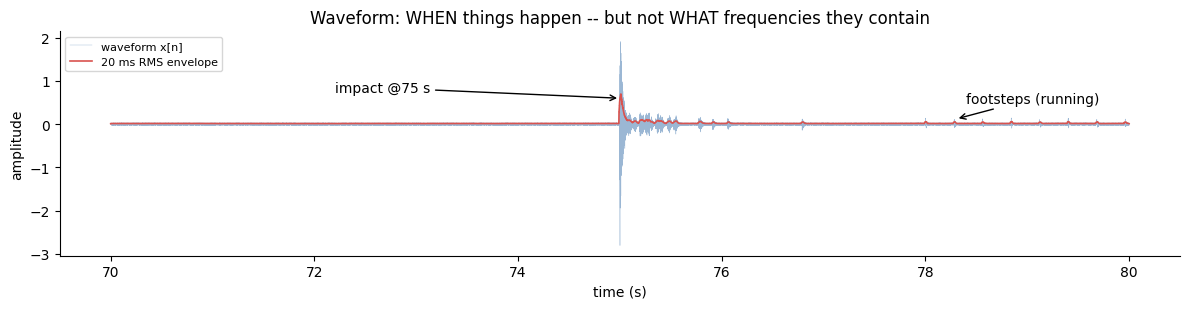

In [24]:
win = int(0.02 * FS)
rms = np.sqrt(np.convolve(x_audio ** 2, np.ones(win) / win, mode="same"))
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t_audio, x_audio, lw=0.3, color="#9bb7d4", label="waveform x[n]")
ax.plot(t_audio, rms, color="#D9534F", lw=1.2, label="20 ms RMS envelope")
ax.annotate("impact @75 s", xy=(75, 0.6), xytext=(72.2, 0.75), arrowprops=dict(arrowstyle="->"))
ax.annotate("footsteps (running)", xy=(78.3, 0.12), xytext=(78.4, 0.5), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Waveform: WHEN things happen -- but not WHAT frequencies they contain")
plt.tight_layout(); plt.show()

## 24. Spectrograms  *(Slides 57–58)*

**What:** A spectrogram splits the signal into short overlapping windows and computes each window's frequency
content: **x-axis = time, y-axis = frequency, colour = magnitude** (Time × Frequency × Magnitude).
Horizontal bands = persistent tones; short vertical stripes = brief broadband events; distinct sounds leave
distinct time–frequency signatures.

**Why:** Below, waveform vs. spectrogram of the same 10 s. Only the spectrogram reveals the 120/240 Hz hum as
horizontal lines, the impact as a vertical stripe, and the **3–7 kHz "tinkle" that persists for ~1 s after the
impact** — the signature of breaking glass.

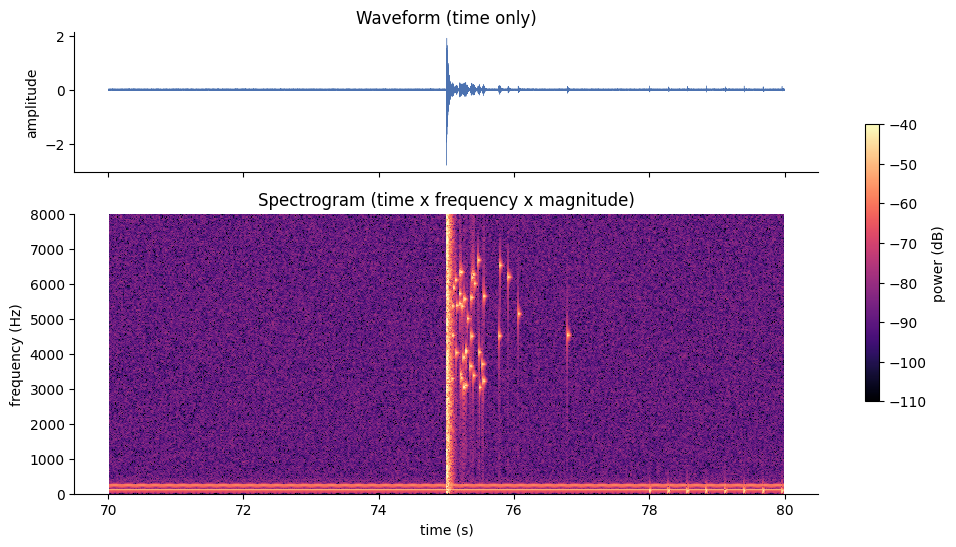

In [25]:
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
axes[0].plot(t_audio, x_audio, lw=0.3, color="#4C72B0"); axes[0].set_ylabel("amplitude")
axes[0].set_title("Waveform (time only)")
pcm = axes[1].pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
axes[1].set_ylabel("frequency (Hz)"); axes[1].set_xlabel("time (s)"); axes[1].set_ylim(0, 8000)
axes[1].set_title("Spectrogram (time x frequency x magnitude)")
plt.colorbar(pcm, ax=axes, label="power (dB)", shrink=0.6)
plt.show()

## 25. Image–Video–Audio Integration (Synchronized Views)  *(Slides 59–60)*

**What:** Multimedia visualization combines modalities that give **complementary** views of the same event,
linked by a common temporal reference: **Frame ↔ Time ↔ Audio segment**. Selecting a moment shows the
corresponding frame, the timeline position and the audio waveform/spectrogram together.

**Why:** Below, one synchronized "moment view" at t = 75 s: what the camera saw, where we are on the timeline,
and what the microphone heard. No single modality tells the whole story.

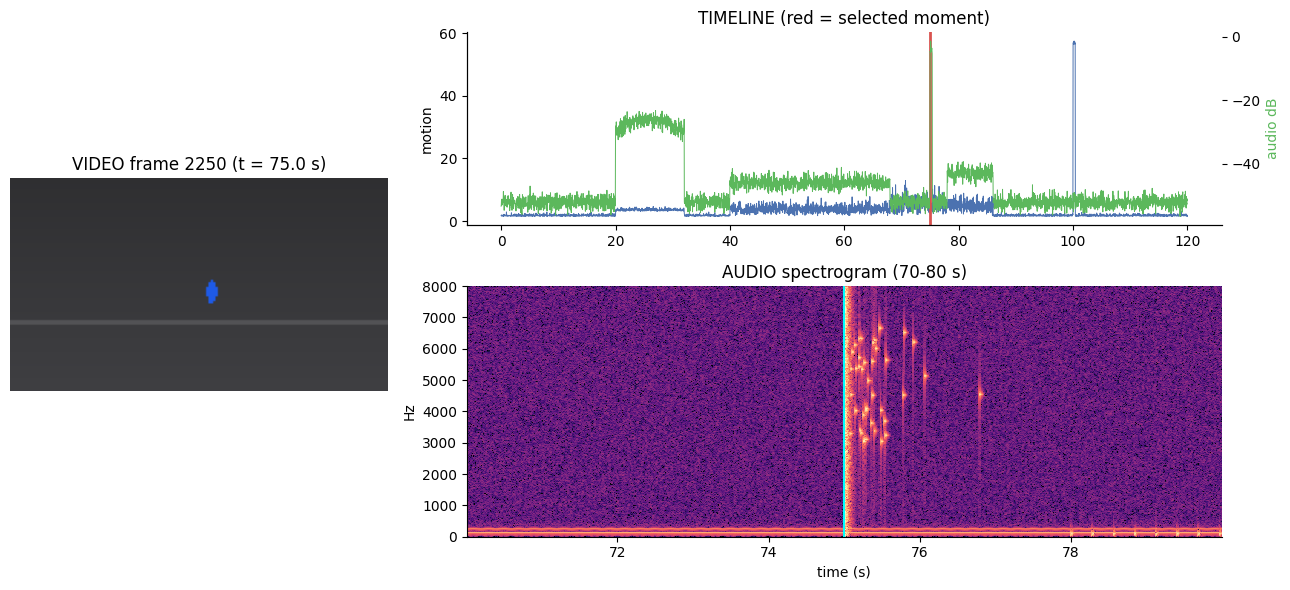

Video: a person is standing still.  Timeline: motion is LOW, audio is at its peak.
Spectrogram: broadband impact + lingering 3-7 kHz energy -> glass breaking, not a footstep or a car.


In [26]:
def moment_view(t_sel):
    i = int(round(t_sel * FPS))
    fig = plt.figure(figsize=(13, 6))
    gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
    ax_f = fig.add_subplot(gs[:, 0]); ax_t = fig.add_subplot(gs[0, 1]); ax_s = fig.add_subplot(gs[1, 1])
    ax_f.imshow(render_frame(cctv.iloc[i])); ax_f.axis("off"); ax_f.set_title(f"VIDEO frame {i} (t = {t_sel:.1f} s)")
    ax_t.plot(cctv.time_s, cctv.motion_energy, color="#4C72B0", lw=0.7, label="motion")
    ax_t2 = ax_t.twinx(); ax_t2.plot(cctv.time_s, cctv.audio_level_db, color="#5cb85c", lw=0.7)
    ax_t.axvline(t_sel, color="#D9534F", lw=2); ax_t.set_title("TIMELINE (red = selected moment)")
    ax_t.set_ylabel("motion"); ax_t2.set_ylabel("audio dB", color="#5cb85c")
    ax_s.pcolormesh(tt + t_audio[0], f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-40)
    ax_s.axvline(t_sel, color="cyan", lw=1.5); ax_s.set_ylim(0, 8000); ax_s.set_ylabel("Hz"); ax_s.set_xlabel("time (s)")
    ax_s.set_title("AUDIO spectrogram (70-80 s)")
    plt.tight_layout(); plt.show()

moment_view(75.0)
print("Video: a person is standing still.  Timeline: motion is LOW, audio is at its peak.")
print("Spectrogram: broadband impact + lingering 3-7 kHz energy -> glass breaking, not a footstep or a car.")

## 26. Challenges and Design Trade-Offs  *(Slide 61)*

**What:** Data volume; **temporal vs. spatial trade-offs** (more time on screen ⇒ less detail per frame);
information overload when modalities are combined; **synchronization** (modalities must be aligned in time);
choosing visual encodings per information type.

**Why:** Below, (1) the raw data volume of our "small" 2-minute clip at real camera resolution, and (2) the
temporal–spatial trade-off: with a fixed 1,600 px wide strip, every extra thumbnail shrinks every other one.

2 min of 1080p RGB at 30 fps, uncompressed: 20.9 GB  (+ 3.7 MB of 16-bit audio)


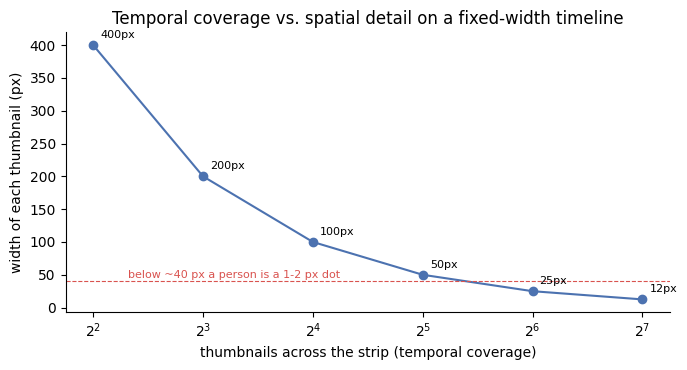

In [27]:
raw = 1920 * 1080 * 3 * 30 * 120
print(f"2 min of 1080p RGB at 30 fps, uncompressed: {raw/1024**3:.1f} GB  (+ {16000*120*2/1024**2:.1f} MB of 16-bit audio)")

strip_px = 1600
n_thumbs = np.array([4, 8, 16, 32, 64, 128])
thumb_w = strip_px / n_thumbs
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(n_thumbs, thumb_w, "o-", color="#4C72B0")
for n_, w_ in zip(n_thumbs, thumb_w):
    ax.annotate(f"{w_:.0f}px", (n_, w_), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xscale("log", base=2); ax.set_xlabel("thumbnails across the strip (temporal coverage)")
ax.set_ylabel("width of each thumbnail (px)"); ax.axhline(40, color="#D9534F", ls="--", lw=0.8)
ax.text(5, 45, "below ~40 px a person is a 1-2 px dot", color="#D9534F", fontsize=8)
ax.set_title("Temporal coverage vs. spatial detail on a fixed-width timeline")
plt.tight_layout(); plt.show()

## Summary: Technique -> When to Use It

| Technique | Solves | Use it when... |
|---|---|---|
| Luminance conversion (weighted RGB) | Naive averages misrepresent perceived brightness | Any grayscale view or contrast computation of a colour image |
| Histogram + contrast stretch | Dark / washed-out / clipped images | Diagnosing exposure before interpreting image content |
| Channel decomposition | Colour structure hidden in the composite | Checking which channel carries a feature or an artifact |
| Feature layers (edges, local contrast) | Raw pixels are too much to inspect | You need *where is the structure / change* rather than the picture itself |
| Contact sheet / image timeline | Long sequences can't be watched | Browsing a collection or a video for recurring patterns |
| x–t slice / space–time cube | Motion hidden across thousands of frames | Seeing speed and timing of moving objects at once |
| Content-based keyframes | Uniform sampling wastes thumbnails | Summarizing a video around its real events |
| Trajectories (colour = time) | Animation is poor for precise speed | Showing direction, turning points and pauses of movers |
| Optical flow (arrows / hue) | "What moved, which way, how much?" | Dense motion analysis between frames |
| Event table + annotated timeline | Analysts search for events, not frames | Surveillance, sports, lab-video review |
| Spectrogram | Waveforms hide frequency content | Telling *what kind* of sound happened, not just when |
| Synchronized multimodal view | Each modality tells only part of the story | Confirming an event across video, timeline and audio |

**Core principle:** multimedia is high-dimensional — good multimedia visualization *reduces* it to the structure,
change and events that matter, while preserving the dimension (space, time or frequency) that carries meaning.